# 15 三维重建：投影图像 → 对应点 → 三角化 → 点云

从带已知相机内外参的合成立方体开始，每个输入点都能追溯到真实 3D 坐标。
这是双视角三角化实验；不冒充完整的 SfM/MVS 或自动从任意照片恢复三维。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cpu


## 1. 定义世界点和相机矩阵

针孔模型 $\lambda [u,v,1]^T=P[X,Y,Z,1]^T$，$P=K[R|t]$。
第二台相机在世界中向右移动 B，其外参平移是 -B；不要把相机位置与外参 t 混为一谈。


In [2]:
f=180.;cx=120.;cy=90.;baseline=.4
K=np.array([[f,0,cx],[0,f,cy],[0,0,1]],float)
P1=K@np.column_stack([np.eye(3),np.zeros(3)])
P2=K@np.column_stack([np.eye(3),np.array([-baseline,0,0])])
cube=np.array([[x,y,z] for z in [2.,3.] for y in [-.4,.4] for x in [-.4,.4]],float)
rng=np.random.default_rng(42)
world=np.vstack([cube, rng.uniform([-.4,-.4,2],[.4,.4,3],size=(60,3))])
def project(P, xyz):
    h=np.column_stack([xyz,np.ones(len(xyz))])@P.T
    return h[:,:2]/h[:,2:3]
uv1=project(P1,world);uv2=project(P2,world)
print("相机 K:\n",K,"\nP2:\n",P2)
print("世界点前4个:\n",world[:4],"\n左图坐标:\n",np.round(uv1[:4],2))


相机 K:
 [[180.   0. 120.]
 [  0. 180.  90.]
 [  0.   0.   1.]] 
P2:
 [[180.   0. 120. -72.]
 [  0. 180.  90.   0.]
 [  0.   0.   1.   0.]]
世界点前4个:
 [[-0.4 -0.4  2. ]
 [ 0.4 -0.4  2. ]
 [-0.4  0.4  2. ]
 [ 0.4  0.4  2. ]] 
左图坐标:
 [[ 84.  54.]
 [156.  54.]
 [ 84. 126.]
 [156. 126.]]


## 2. 将投影点画成两幅输入图

点的颜色和编号表示已知对应关系。真实重建必须自己检测/匹配特征并剔除错误匹配；本课把对应关系作为已知输入，集中学习几何过程。


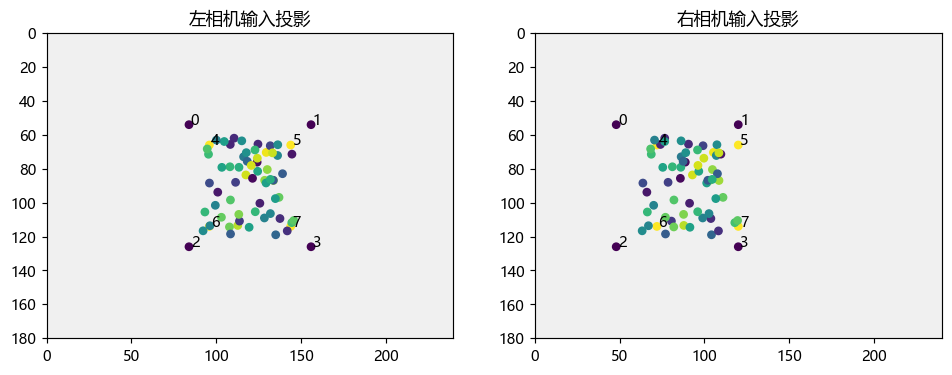

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/15_reconstruction_inputs.png')

In [3]:
fig,axs=plt.subplots(1,2,figsize=(11,4))
for ax,uv,title in zip(axs,[uv1,uv2],["左相机输入投影", "右相机输入投影"]):
    ax.set_facecolor("#f0f0f0");ax.scatter(uv[:,0],uv[:,1],c=world[:,2],cmap="viridis",s=25)
    for i in range(8):ax.text(uv[i,0]+1,uv[i,1],str(i))
    ax.set_xlim(0,240);ax.set_ylim(180,0);ax.set_aspect("equal");ax.set_title(title)
save_figure("15_reconstruction_inputs")


## 3. 三角化与齐次归一化

维度怎么读：每台相机的二维对应点是 `[N,2]`，列按 `(u,v)` 排列；OpenCV 接口转置为 `[2,N]`。投影矩阵为 `[3,4]`。三角化给出 `[4,N]` 齐次点，前三行除以第四行后，转置得到 `[N,3]` 的 `(X,Y,Z)` 世界坐标。齐次坐标本身不直接表示米，也不是 RGB 像素值。

OpenCV 输出 4×N 齐次点 $[X_h,Y_h,Z_h,W]^T$，需除以 W 得到欧式坐标。


In [4]:
homogeneous=cv2.triangulatePoints(P1,P2,uv1.T,uv2.T)
reconstructed=(homogeneous[:3]/homogeneous[3:4]).T
print("齐次矩阵前4列:\n",np.round(homogeneous[:,:4],3))
print("重建点前4个:\n",np.round(reconstructed[:4],3))
rmse=np.sqrt(np.mean(np.sum((reconstructed-world)**2,axis=1)))
reproj=np.mean(np.linalg.norm(project(P1,reconstructed)-uv1,axis=1))
print(f"无噪声 3D RMSE={rmse:.8f} m；左图重投影误差={reproj:.8f} px")
assert rmse<1e-5


齐次矩阵前4列:
 [[ 0.173 -0.173  0.173 -0.173]
 [ 0.173  0.173 -0.173 -0.173]
 [-0.867 -0.867 -0.867 -0.867]
 [-0.434 -0.434 -0.434 -0.434]]
重建点前4个:
 [[-0.4 -0.4  2. ]
 [ 0.4 -0.4  2. ]
 [-0.4  0.4  2. ]
 [ 0.4  0.4  2. ]]
无噪声 3D RMSE=0.00000000 m；左图重投影误差=0.00000000 px


## 4. 加入匹配噪声，观察实际误差

给两张图的坐标分别加 0.3 px 高斯噪声，再重复三角化。重投影误差很小并不自动保证三维误差很小。


有噪声 3D RMSE=0.0398 m


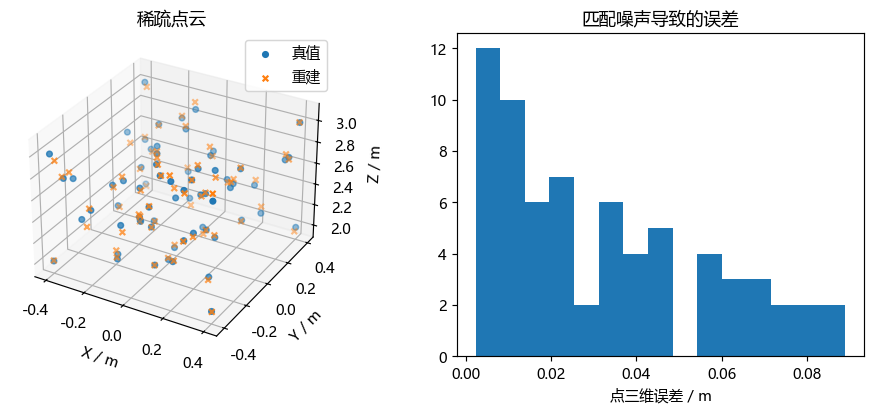

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/15_reconstruction_outputs.png')

In [5]:
uv1_noisy=uv1+rng.normal(0,.3,uv1.shape)
uv2_noisy=uv2+rng.normal(0,.3,uv2.shape)
h=cv2.triangulatePoints(P1,P2,uv1_noisy.T,uv2_noisy.T)
xyz_noisy=(h[:3]/h[3:4]).T
point_error=np.linalg.norm(xyz_noisy-world,axis=1)
print(f"有噪声 3D RMSE={np.sqrt(np.mean(point_error**2)):.4f} m")
fig=plt.figure(figsize=(11,4))
ax=fig.add_subplot(121,projection="3d")
ax.scatter(world[:,0],world[:,1],world[:,2],label="真值",s=15)
ax.scatter(xyz_noisy[:,0],xyz_noisy[:,1],xyz_noisy[:,2],label="重建",marker="x",s=15)
ax.set_xlabel("X / m");ax.set_ylabel("Y / m");ax.set_zlabel("Z / m");ax.legend();ax.set_title("稀疏点云")
ax2=fig.add_subplot(122);ax2.hist(point_error,bins=15);ax2.set_xlabel("点三维误差 / m");ax2.set_title("匹配噪声导致的误差")
save_figure("15_reconstruction_outputs")


## 5. 输出可查看的点云文件

保存 PLY 文本点云，可用支持 PLY 的三维软件打开。它只有点，没有表面网格、纹理或完整物体表面。


In [6]:
out_dir=ROOT/"outputs";out_dir.mkdir(exist_ok=True)
ply=out_dir/"15_reconstructed_points.ply"
with ply.open("w",encoding="utf-8") as file:
    file.write(f"ply\nformat ascii 1.0\nelement vertex {len(xyz_noisy)}\nproperty float x\nproperty float y\nproperty float z\nend_header\n")
    np.savetxt(file,xyz_noisy,fmt="%.6f")
print("点云已保存:",ply)


点云已保存: D:\workspace\cv\cv-beginner-course\outputs\15_reconstructed_points.ply


## 6. 完整重建还缺什么

实际 SfM/MVS 流程包括：相机标定、特征检测与匹配、几何验证、位姿估计、三角化、束调整、稠密重建、网格与纹理。
练习：把基线从 0.4 m 改为 0.05 m，在同样坐标噪声下重新计算；解释误差为什么变化。

来源：[OpenCV triangulatePoints](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html)、[COLMAP 官方教程](https://colmap.github.io/tutorial.html)。
